In [1]:
from config import *

from Image_charge_3d import *

import scipy.integrate

In [23]:
class potential_due_sheet: 

    def __init__(self, d, charge_density, ep_qw = 11.7, ep_sige= 11.7, ep_ox=8, t_sige=10, t_ox=15):

        self.d = d   ## charge sheet is placed at a distance d 
        self.cd = charge_density 
        self.ep_qw = ep_qw
        self.ep_sige = ep_sige
        self.ep_ox= ep_ox
        self.t_sige = t_sige
        self.t_ox = t_ox

    def image_charge(self,  xp, yp):

        img_charge = Image_charge_calculator(q_ct=1, z_ct=self.d, y_ct = yp, x_ct= xp, ep_qw = self.ep_qw, ep_sige= self.ep_sige, ep_ox=self.ep_ox, t_sige=self.t_sige, t_ox=self.t_ox, r=1e-3).calc_image_charges()

        return img_charge


    def greens_function(self, x, y, z, xp, yp):

        img_charge = Image_charge_calculator(q_ct=1, z_ct=self.d, y_ct = yp, x_ct= xp, ep_qw = self.ep_qw, ep_sige= self.ep_sige, ep_ox=self.ep_ox, t_sige=self.t_sige, t_ox=self.t_ox, r=1e-3).calc_image_charges()

        Gfn = 0

        if z <= self.t_ox :

        #print('a')

            for ic in img_charge[2]:  
                ### q3s

                Gfn = Gfn + ic[0]/math.sqrt((x- xp)**2+(y- yp)**2+(z-ic[1])**2)

            for ic in img_charge[1]:
                ### q4s

                Gfn = Gfn + ic[0]/math.sqrt((x- xp)**2+(y- yp)**2+(z-ic[1])**2)
        
        elif z <= self.t_sige and z> self.t_ox :

            for ic in img_charge[3]:  
                ### q2s

                Gfn = Gfn + ic[0]/math.sqrt((x- xp)**2+(y- yp)**2+(z-ic[1])**2)

            for ic in img_charge[4]:
                ### q1s

                Gfn = Gfn + ic[0]/math.sqrt((x- xp)**2+(y- yp)**2+(z-ic[1])**2)

        else :

            for ic in img_charge[0]:
                ### q5s

                Gfn = Gfn + ic[0]/math.sqrt((x- xp)**2+(y- yp)**2+(z-ic[1])**2)
        
        return Gfn 


    def integrate_greens_function(self, x, y, z, xp_min, xp_max, yp_min, yp_max):

        result, error = scipy.integrate.dblquad(
            lambda xp, yp: self.greens_function(x, y, z, xp, yp),
            yp_min, yp_max,  # Integration limits for yp (outer integral)
            lambda yp: xp_min, lambda yp: xp_max  # Integration limits for xp (inner integral)
        )

        Area = (xp_max-xp_min)*(yp_max-yp_min)

        if z <= self.t_ox :

            result = 1/self.ep_ox*result

        elif z<= self.t_sige and z>self.t_ox:

            result = 1/self.ep_sige*result

        else:

            result = 1/self.ep_qw*result


        return result, error
    
    def integrate_gfn_simps(self, x, y, z, xp_min, xp_max, yp_min, yp_max, num_points):

        xp_vals = np.linspace(xp_min, xp_max, num_points)
        yp_vals = np.linspace(yp_min, yp_max, num_points)
        xp_grid, yp_grid = np.meshgrid(xp_vals, yp_vals)

        greens_values = np.vectorize(self.greens_function)(x, y, z, xp_grid, yp_grid)
        result =  scipy.integrate.simps(scipy.integrate.simps(greens_values, yp_vals), xp_vals)
        if z <= self.t_ox :

            result = 1/self.ep_ox*result

        elif z<= self.t_sige and z>self.t_ox:

            result = 1/self.ep_sige*result

        else:

            result = 1/self.ep_qw*result


        return result

    
    def integrate_gfn_trapz(self, x, y, z, xp_min, xp_max, yp_min, yp_max, num_points):

        xp_vals = np.linspace(xp_min, xp_max, num_points)
        yp_vals = np.linspace(yp_min, yp_max, num_points)
        xp_grid, yp_grid = np.meshgrid(xp_vals, yp_vals)

        greens_values = np.vectorize(self.greens_function)(x, y, z, xp_grid, yp_grid)
        result = np.trapz(np.trapz(greens_values, yp_vals), xp_vals)

        if z <= self.t_ox :

            result = 1/self.ep_ox*result

        elif z<= self.t_sige:

            result = 1/self.ep_sige*result

        else:

            result = 1/self.ep_qw*result


        return result




In [3]:

D = 10
X = 0 
Y = 0
Z = 5 

SIG = 1

XP_MIN= -1000
XP_MAX = 1000
YP_MIN = -1000
YP_MAX = 1000

Mod = potential_due_sheet(D, SIG)

V = Mod.integrate_greens_function(X, Y, Z, XP_MIN, XP_MAX, YP_MIN, YP_MAX)

print(V)

(885.2029170358783, 9.749631039582957e-05)


In [4]:

D = 10
X = 0 
Y = 0
Z = 4 

SIG = 1

XP_MIN= -1000
XP_MAX = 1000
YP_MIN = -1000
YP_MAX = 1000

Mod = potential_due_sheet(D, SIG)

V = Mod.integrate_greens_function(X, Y, Z, XP_MIN, XP_MAX, YP_MIN, YP_MAX)

print(V)

(882.8712752072549, 6.174306209263784e-05)


In [5]:

D = 10
X = 0 
Y = 0
Z = 0 

SIG = 1

XP_MIN= -1000
XP_MAX = 1000
YP_MIN = -1000
YP_MAX = 1000

Mod = potential_due_sheet(D, SIG)

V = Mod.integrate_greens_function(X, Y, Z, XP_MIN, XP_MAX, YP_MIN, YP_MAX)

print(V)

(873.5517800512188, 8.436291015481712e-05)


In [6]:

D = 10
X = 0 
Y = 0
Z = 100

SIG = 1

XP_MIN= -1000
XP_MAX = 1000
YP_MIN = -1000
YP_MAX = 1000

Mod = potential_due_sheet(D, SIG)

V = Mod.integrate_greens_function(X, Y, Z, XP_MIN, XP_MAX, YP_MIN, YP_MAX)

print(V)

(570.4718019469236, 8.108875476499995e-07)


In [8]:
D = 10
X = 7 
Y = 9
Z = 100

SIG = 1

XP_MIN= -1000
XP_MAX = 1000
YP_MIN = -1000
YP_MAX = 1000

AREA= (XP_MAX-XP_MIN)*(YP_MAX-YP_MIN)

Mod = potential_due_sheet(D, SIG)

V = Mod.integrate_greens_function(X, Y, Z, XP_MIN, XP_MAX, YP_MIN, YP_MAX)

print(V[0]/AREA, V[1])

0.00014261403161682743 6.205984479987073e-07


In [9]:
D = 10
X = 7 
Y = 20
Z = 100

SIG = 1

XP_MIN= -10000
XP_MAX = 10000
YP_MIN = -10000
YP_MAX = 10000


AREA= (XP_MAX-XP_MIN)*(YP_MAX-YP_MIN)

Mod = potential_due_sheet(D, SIG)

V = Mod.integrate_greens_function(X, Y, Z, XP_MIN, XP_MAX, YP_MIN, YP_MAX)

print(V[0]/AREA, V[1])

1.4984743516473505e-05 6.236790500560585e-05


In [10]:
D = 10
X = 30 
Y = 20
Z = 100

SIG = 1

XP_MIN= -10000
XP_MAX = 10000
YP_MIN = -10000
YP_MAX = 10000


AREA= (XP_MAX-XP_MIN)*(YP_MAX-YP_MIN)

Mod = potential_due_sheet(D, SIG)

V = Mod.integrate_greens_function(X, Y, Z, XP_MIN, XP_MAX, YP_MIN, YP_MAX)

print(V[0]/AREA)

1.49847178014449e-05


In [11]:
Z = np.linspace(0, 100, 23)
Z

array([  0.        ,   4.54545455,   9.09090909,  13.63636364,
        18.18181818,  22.72727273,  27.27272727,  31.81818182,
        36.36363636,  40.90909091,  45.45454545,  50.        ,
        54.54545455,  59.09090909,  63.63636364,  68.18181818,
        72.72727273,  77.27272727,  81.81818182,  86.36363636,
        90.90909091,  95.45454545, 100.        ])

[3.00000000e-04 1.11568462e+00 2.23106923e+00 3.34645385e+00
 4.46183846e+00 5.57722308e+00 6.69260769e+00 7.80799231e+00
 8.92337692e+00 1.00387615e+01 1.11541462e+01 1.22695308e+01
 1.33849154e+01 1.45003000e+01 1.56156846e+01 1.67310692e+01
 1.78464538e+01 1.89618385e+01 2.00772231e+01 2.11926077e+01
 2.23079923e+01 2.34233769e+01 2.45387615e+01 2.56541462e+01
 2.67695308e+01 2.78849154e+01 2.90003000e+01]
0
3
6
9
12
15
18
21
24


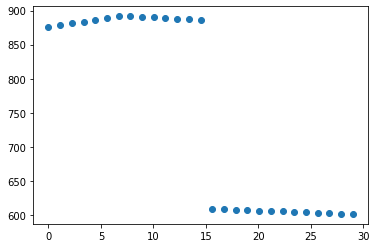

In [14]:

D = 7
X = 0
Y = 1

epsilon = 3e-4  # A tiny shift

Z = np.linspace(0, 29, 27) + epsilon

print(Z)

SIG = 1

XP_MIN= -1000
XP_MAX = 1000
YP_MIN = -1000
YP_MAX = 1000

Mod = potential_due_sheet(D, SIG, t_ox=15, t_sige=10)
V = np.empty((Z.shape[0]))
err =  np.empty((Z.shape[0]))

for i in range(Z.shape[0]):

    V[i], err[i] = Mod.integrate_greens_function(X, Y, Z[i], XP_MIN, XP_MAX, YP_MIN, YP_MAX)

    if i%3 == 0:

        print(i)

plt.scatter(Z, V)



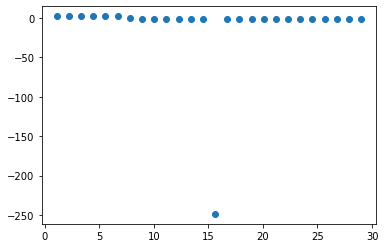

In [15]:
E = np.diff(V) / np.diff(Z)

plt.scatter(Z[1:], E)

In [20]:
print(np.round(E))

[   2.    2.    2.    2.    2.    2.    0.   -1.   -1.   -1.   -1.   -1.
   -1. -249.   -1.   -1.   -1.   -1.   -1.   -1.   -1.   -1.   -1.   -1.
   -1.   -1.]


In [22]:
Q = Mod.image_charge(0,0)
print(Q[0]) ##q5
print(Q[1]) ##q4
print(Q[2]) ##q3
print(Q[3]) ##q2
print(Q[4]) ##q1


[(0.001478058498477397, -113, 10, 'q5k'), (0.007869662816217492, -83, 8, 'q5k'), (0.041900637156617467, -53, 6, 'q5k'), (0.22309258161766599, -23, 4, 'q5k'), (1.1878172588832487, 7, 2, 'q5k'), (-0.001478058498477397, -127, 10, 'q5k'), (-0.007869662816217492, -97, 8, 'q5k'), (-0.041900637156617467, -67, 6, 'q5k'), (-0.22309258161766599, -37, 4, 'q5k'), (-1.1878172588832487, -7, 2, 'q5k')]
[(1, 7, 0, 'q4j'), (-1, -7, 0, 'q4j'), (0.1878172588832487, -23, 2, 'q4j'), (0.03527532273441727, -53, 4, 'q4j'), (0.006625314422200197, -83, 6, 'q4j'), (0.0012443483940172957, -113, 8, 'q4j'), (-0.1878172588832487, -37, 2, 'q4j'), (-0.03527532273441727, -67, 4, 'q4j'), (-0.006625314422200197, -97, 6, 'q4j'), (-0.0012443483940172957, -127, 8, 'q4j')]
[(-0.1878172588832487, 23, 1, 'q3j'), (-0.03527532273441727, 53, 3, 'q3j'), (-0.006625314422200197, 83, 5, 'q3j'), (-0.0012443483940172957, 113, 7, 'q3j'), (-0.0002337101044601012, 143, 9, 'q3j'), (0.1878172588832487, 37, 1, 'q3j'), (0.03527532273441727, 6

[3.00000e-04 2.90030e+00 5.80030e+00 8.70030e+00 1.16003e+01 1.45003e+01
 1.74003e+01 2.03003e+01 2.32003e+01 2.61003e+01 2.90003e+01]


C:\Users\Vivrekar\AppData\Local\Temp\3\ipykernel_49488\2040358684.py:94: DeprecationWarning: 'scipy.integrate.simps' is deprecated in favour of 'scipy.integrate.simpson' and will be removed in SciPy 1.14.0
  result =  scipy.integrate.simps(scipy.integrate.simps(greens_values, yp_vals), xp_vals)


0
3
6
9


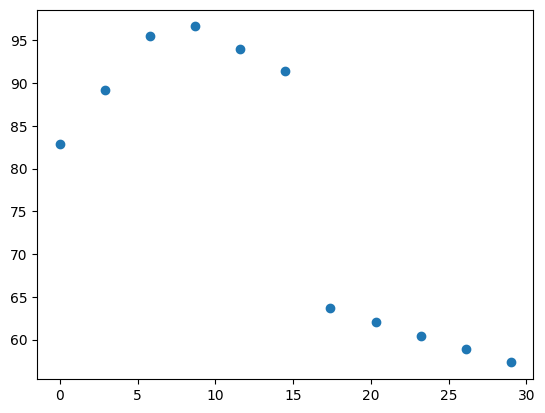

In [24]:
D = 7
X = 0
Y = 1

epsilon = 3e-4  # A tiny shift

Z = np.linspace(0, 29, 11) + epsilon

print(Z)

SIG = 1

XP_MIN= -100
XP_MAX = 100
YP_MIN = -100
YP_MAX = 100

Mod = potential_due_sheet(D, SIG, t_ox=15, t_sige=10)
V = np.empty((Z.shape[0]))
err =  np.empty((Z.shape[0]))

for i in range(Z.shape[0]):

    V[i] = Mod.integrate_gfn_simps(X, Y, Z[i], XP_MIN, XP_MAX, YP_MIN, YP_MAX,1000)

    if i%3 == 0:

        print(i)

plt.scatter(Z, V)

[3.00000e-04 2.90030e+00 5.80030e+00 8.70030e+00 1.16003e+01 1.45003e+01
 1.74003e+01 2.03003e+01 2.32003e+01 2.61003e+01 2.90003e+01]
0
3
6
9


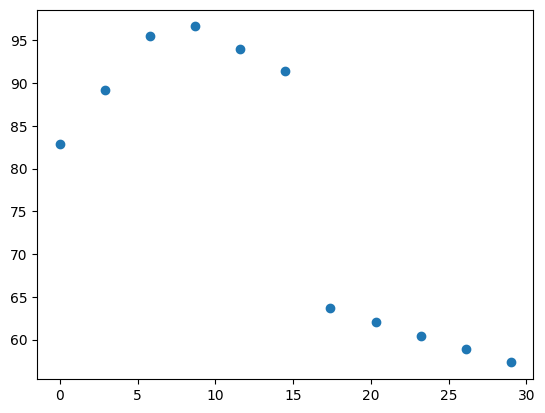

In [25]:
D = 7
X = 0
Y = 1

epsilon = 3e-4  # A tiny shift

Z = np.linspace(0, 29, 11) + epsilon

print(Z)

SIG = 1

XP_MIN= -100
XP_MAX = 100
YP_MIN = -100
YP_MAX = 100

Mod = potential_due_sheet(D, SIG, t_ox=15, t_sige=10)
V = np.empty((Z.shape[0]))
err =  np.empty((Z.shape[0]))

for i in range(Z.shape[0]):

    V[i] = Mod.integrate_gfn_trapz(X, Y, Z[i], XP_MIN, XP_MAX, YP_MIN, YP_MAX,1000)

    if i%3 == 0:

        print(i)

plt.scatter(Z, V)

[3.00000e-04 1.45030e+00 2.90030e+00 4.35030e+00 5.80030e+00 7.25030e+00
 8.70030e+00 1.01503e+01 1.16003e+01 1.30503e+01 1.45003e+01 1.59503e+01
 1.74003e+01 1.88503e+01 2.03003e+01 2.17503e+01 2.32003e+01 2.46503e+01
 2.61003e+01 2.75503e+01 2.90003e+01]


C:\Users\Vivrekar\AppData\Local\Temp\3\ipykernel_49488\2040358684.py:94: DeprecationWarning: 'scipy.integrate.simps' is deprecated in favour of 'scipy.integrate.simpson' and will be removed in SciPy 1.14.0
  result =  scipy.integrate.simps(scipy.integrate.simps(greens_values, yp_vals), xp_vals)


0
3
6
9
12
15
18


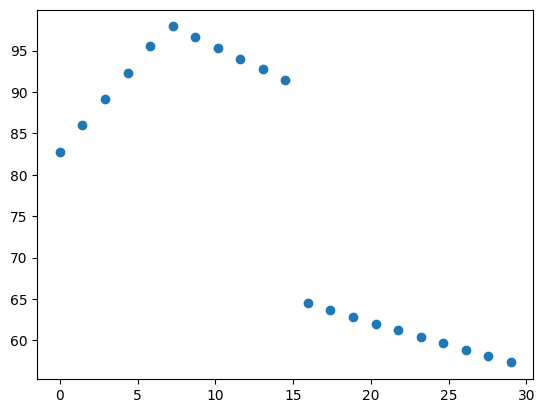

In [26]:
D = 7
X = 0
Y = 1

epsilon = 3e-4  # A tiny shift

Z = np.linspace(0, 29, 21) + epsilon

print(Z)

SIG = 1

XP_MIN= -100
XP_MAX = 100
YP_MIN = -100
YP_MAX = 100

Mod = potential_due_sheet(D, SIG, t_ox=15, t_sige=10)
V = np.empty((Z.shape[0]))
err =  np.empty((Z.shape[0]))

for i in range(Z.shape[0]):

    V[i] = Mod.integrate_gfn_simps(X, Y, Z[i], XP_MIN, XP_MAX, YP_MIN, YP_MAX,500)

    if i%3 == 0:

        print(i)

plt.scatter(Z, V)

In [27]:
class Changed_gfn(potential_due_sheet):

    def greens_function(self, x, y, z, xp, yp):

        img_charge = Image_charge_calculator(q_ct=1, z_ct=self.d, y_ct = yp, x_ct= xp, ep_qw = self.ep_qw, ep_sige= self.ep_sige, ep_ox=self.ep_ox, t_sige=self.t_sige, t_ox=self.t_ox, r=1e-3).calc_image_charges()

        Gfn = 1/math.sqrt((x - xp)**2+(y - yp)**2+(z-self.d)**2)

        #if z <= self.t_ox :

        #print('a')

        for ic in img_charge[2]:  
            ### q3s

            Gfn = Gfn + ic[0]/math.sqrt((x- xp)**2+(y- yp)**2+(z-ic[1])**2)

        for ic in img_charge[1]:
            ### q4s

                Gfn = Gfn + ic[0]/math.sqrt((x- xp)**2+(y- yp)**2+(z-ic[1])**2)
        
        return Gfn 

[3.00000e-04 1.45030e+00 2.90030e+00 4.35030e+00 5.80030e+00 7.25030e+00
 8.70030e+00 1.01503e+01 1.16003e+01 1.30503e+01 1.45003e+01 1.59503e+01
 1.74003e+01 1.88503e+01 2.03003e+01 2.17503e+01 2.32003e+01 2.46503e+01
 2.61003e+01 2.75503e+01 2.90003e+01]


C:\Users\Vivrekar\AppData\Local\Temp\3\ipykernel_49488\2040358684.py:94: DeprecationWarning: 'scipy.integrate.simps' is deprecated in favour of 'scipy.integrate.simpson' and will be removed in SciPy 1.14.0
  result =  scipy.integrate.simps(scipy.integrate.simps(greens_values, yp_vals), xp_vals)


0
3
6
9
12
15
18


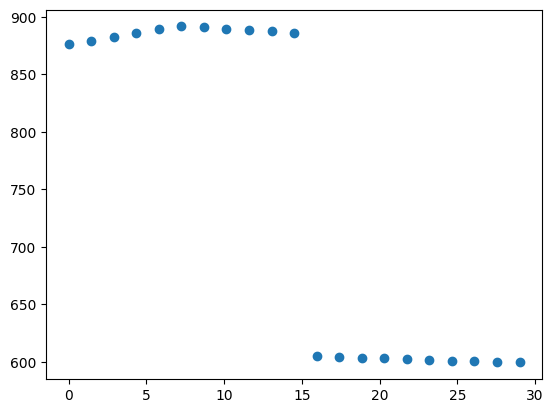

In [28]:
D = 7
X = 0
Y = 1

epsilon = 3e-4  # A tiny shift

Z = np.linspace(0, 29, 21) + epsilon

print(Z)

SIG = 1

XP_MIN= -1000
XP_MAX = 1000
YP_MIN = -1000
YP_MAX = 1000

Mod = Changed_gfn(D, SIG, t_ox=15, t_sige=10)
V = np.empty((Z.shape[0]))
err =  np.empty((Z.shape[0]))

for i in range(Z.shape[0]):

    V[i] = Mod.integrate_gfn_simps(X, Y, Z[i], XP_MIN, XP_MAX, YP_MIN, YP_MAX,1000)

    if i%3 == 0:

        print(i)

plt.scatter(Z, V)

[3.00000e-04 1.45030e+00 2.90030e+00 4.35030e+00 5.80030e+00 7.25030e+00
 8.70030e+00 1.01503e+01 1.16003e+01 1.30503e+01 1.45003e+01 1.59503e+01
 1.74003e+01 1.88503e+01 2.03003e+01 2.17503e+01 2.32003e+01 2.46503e+01
 2.61003e+01 2.75503e+01 2.90003e+01]


C:\Users\Vivrekar\AppData\Local\Temp\3\ipykernel_49488\2040358684.py:94: DeprecationWarning: 'scipy.integrate.simps' is deprecated in favour of 'scipy.integrate.simpson' and will be removed in SciPy 1.14.0
  result =  scipy.integrate.simps(scipy.integrate.simps(greens_values, yp_vals), xp_vals)


0
3
6
9
12
15
18


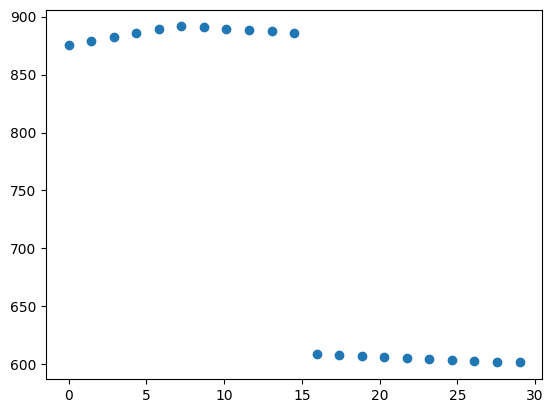

In [30]:
D = 7
X = 0
Y = 1

epsilon = 3e-4  # A tiny shift

Z = np.linspace(0, 29, 21) + epsilon

print(Z)

SIG = 1

XP_MIN= -1000
XP_MAX = 1000
YP_MIN = -1000
YP_MAX = 1000

Mod = potential_due_sheet(D, SIG, t_ox=15, t_sige=10)
V = np.empty((Z.shape[0]))
err =  np.empty((Z.shape[0]))

for i in range(Z.shape[0]):

    V[i] = Mod.integrate_gfn_simps(X, Y, Z[i], XP_MIN, XP_MAX, YP_MIN, YP_MAX,1000)

    if i%3 == 0:

        print(i)

plt.scatter(Z, V)

In [35]:
class New_Image_Charge_Calculator(Image_charge_calculator):

    def rule_iii(self, q3i, z3i, level):

        #if abs(q3i / self.q_ct) < self.delta:
        #    return  # Termination condition

        q4j = -1 * q3i
        z4j = -z3i
        
        self.image_charges_q4s.append((q4j, z4j, level, 'q4j'))
        self.rule_iv(q4j, z4j, level + 1)


class New_potential_due_Sheet(potential_due_sheet):

    def image_charge(self,  xp, yp):

        img_charge = New_Image_Charge_Calculator(q_ct=1, z_ct=self.d, y_ct = yp, x_ct= xp, ep_qw = self.ep_qw, ep_sige= self.ep_sige, ep_ox=self.ep_ox, t_sige=self.t_sige, t_ox=self.t_ox, r=1e-3).calc_image_charges()

        return img_charge


    def greens_function(self, x, y, z, xp, yp):

        img_charge = New_Image_Charge_Calculator(q_ct=1, z_ct=self.d, y_ct = yp, x_ct= xp, ep_qw = self.ep_qw, ep_sige= self.ep_sige, ep_ox=self.ep_ox, t_sige=self.t_sige, t_ox=self.t_ox, r=1e-3).calc_image_charges()

        Gfn = 0

        if z <= self.t_ox :

        #print('a')

            for ic in img_charge[2]:  
                ### q3s

                Gfn = Gfn + ic[0]/math.sqrt((x- xp)**2+(y- yp)**2+(z-ic[1])**2)

            for ic in img_charge[1]:
                ### q4s

                Gfn = Gfn + ic[0]/math.sqrt((x- xp)**2+(y- yp)**2+(z-ic[1])**2)
        
        elif z <= self.t_sige and z> self.t_ox :

            for ic in img_charge[3]:  
                ### q2s

                Gfn = Gfn + ic[0]/math.sqrt((x- xp)**2+(y- yp)**2+(z-ic[1])**2)

            for ic in img_charge[4]:
                ### q1s

                Gfn = Gfn + ic[0]/math.sqrt((x- xp)**2+(y- yp)**2+(z-ic[1])**2)

        else :

            for ic in img_charge[0]:
                ### q5s

                Gfn = Gfn + ic[0]/math.sqrt((x- xp)**2+(y- yp)**2+(z-ic[1])**2)
        
        return Gfn 

In [33]:
D = 7
X = 0
Y = 1

epsilon = 3e-5  # A tiny shift

Z = 1

print(Z)

SIG = 1

XP_MIN= -1000
XP_MAX = 1000
YP_MIN = -1000
YP_MAX = 1000

Mod = New_potential_due_Sheet(D, SIG, t_ox=15, t_sige=10).image_charge(0,0)

print(Mod[1])
print(Mod[2])


1
[(1, 7, 0, 'q4j'), (-1, -7, 0, 'q4j'), (0.1878172588832487, -23, 2, 'q4j'), (0.03527532273441727, -53, 4, 'q4j'), (0.006625314422200197, -83, 6, 'q4j'), (0.0012443483940172957, -113, 8, 'q4j'), (0.0002337101044601012, -143, 10, 'q4j'), (-0.1878172588832487, -37, 2, 'q4j'), (-0.03527532273441727, -67, 4, 'q4j'), (-0.006625314422200197, -97, 6, 'q4j'), (-0.0012443483940172957, -127, 8, 'q4j'), (-0.0002337101044601012, -157, 10, 'q4j')]
[(-0.1878172588832487, 23, 1, 'q3j'), (-0.03527532273441727, 53, 3, 'q3j'), (-0.006625314422200197, 83, 5, 'q3j'), (-0.0012443483940172957, 113, 7, 'q3j'), (-0.0002337101044601012, 143, 9, 'q3j'), (0.1878172588832487, 37, 1, 'q3j'), (0.03527532273441727, 67, 3, 'q3j'), (0.006625314422200197, 97, 5, 'q3j'), (0.0012443483940172957, 127, 7, 'q3j'), (0.0002337101044601012, 157, 9, 'q3j')]


[3.000000e-05 1.500030e+00 3.000030e+00 4.500030e+00 6.000030e+00
 7.500030e+00 9.000030e+00 1.050003e+01 1.200003e+01 1.350003e+01
 1.500003e+01]


C:\Users\Vivrekar\AppData\Local\Temp\3\ipykernel_49488\2040358684.py:94: DeprecationWarning: 'scipy.integrate.simps' is deprecated in favour of 'scipy.integrate.simpson' and will be removed in SciPy 1.14.0
  result =  scipy.integrate.simps(scipy.integrate.simps(greens_values, yp_vals), xp_vals)


0
3
6
9


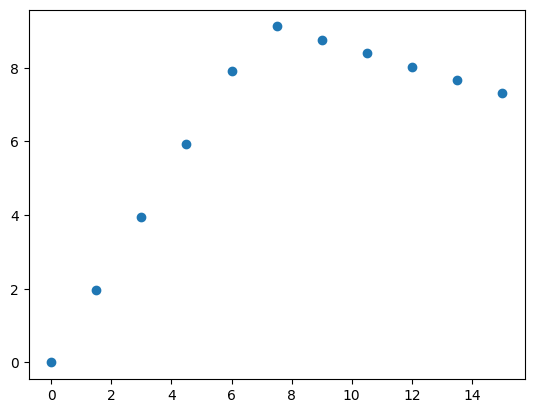

In [43]:
D = 7
X = 0
Y = 1

epsilon = 3e-5  # A tiny shift

#Z = np.linspace(0, 29, 21) + epsilon
Z = np.linspace(0, 15, 11) + epsilon

print(Z)

SIG = 1

XP_MIN= -50
XP_MAX = 50
YP_MIN = -50
YP_MAX = 50

Mod = New_potential_due_Sheet(D, SIG, t_ox=15, t_sige=10)
V = np.empty((Z.shape[0]))
err =  np.empty((Z.shape[0]))

for i in range(Z.shape[0]):

    V[i] = Mod.integrate_gfn_simps(X, Y, Z[i], XP_MIN, XP_MAX, YP_MIN, YP_MAX,1000)

    if i%3 == 0:

        print(i)

plt.scatter(Z, V)

array([ 0.1 ,  0.11,  0.11,  0.11,  0.06, -0.02, -0.02, -0.02, -0.02,
       -0.02])

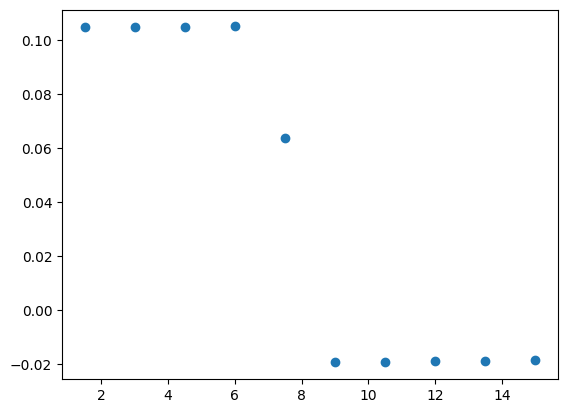

In [45]:
E = np.diff(V) / np.diff(Z)

plt.scatter(Z[1:], E)

np.round(E,2)

In [42]:
np.save("potential_{}X{}_sheet_in_Front_of_conductor_counts{}.npy".format(XP_MAX, YP_MAX, 1000), V)